# Metal GPU kernels through the compiler's eyes

**Question:** If each GPU kernel is represented as a vector built from its compiler IR, do similar kernels end up close together? And does compiler optimization (`-O0` → optimized) change every kernel in a similar way?

**Approach:**
1. Write 8 small Metal kernels covering different kinds of GPU work
2. Compile each to **AIR** (Apple's LLVM-based IR) at `-O0` and at the default optimization level
3. Represent each compiled kernel as a vector of normalized instruction counts
4. Compare the vectors with cosine similarity and PCA, and measure how optimization moves them

**Requirements:** macOS with Xcode (the Metal compiler only exists on macOS), plus `pip install -r requirements.txt`.

## 1. Background

Apple's GPU compilation pipeline:

```
kernel.metal  (Metal Shading Language)
   │  Metal frontend (Clang-based)
   ▼
AIR = LLVM IR + Apple GPU intrinsics      ← last readable stage
   │
   ▼
Apple GPU backend (closed source) → M-series machine code
```

Because the backend is closed, this project studies the **frontend and middle-end**, where the IR is visible.

At `-O0` the compiler gives every variable a stack slot (`alloca`) and reads/writes it through `load`/`store`. At the default level, passes such as **mem2reg**, constant folding, dead code elimination and instruction combining remove most of that overhead.

## 2. Representation: a "bag of instructions"

ML-guided compilers need programs as fixed-length vectors. IR2Vec does this with learned embeddings of IR entities (symbolic and flow-aware variants). As a simple, fully explainable baseline, I count how often each instruction type appears, analogous to bag-of-words in NLP, and divide by the total so kernels of different sizes are comparable.

Limitation: counts ignore instruction order and data flow, so two different programs can share a vector. Flow-aware embeddings like IR2Vec's address this.

## 3. Kernels

| Kernel | Operation | Kind of GPU work |
|---|---|---|
| `vector_add` | c = a + b | elementwise |
| `saxpy` | y = a·x + y | elementwise with a constant |
| `relu` | max(x, 0) | elementwise with comparison |
| `sigmoid` | 1 / (1 + e⁻ˣ) | elementwise with a math call |
| `blur3` | mean of 3 neighbours | stencil with boundary branch |
| `matmul` | C = A × B | loop of multiply-adds |
| `reduce_sum` | block sum | threadgroup memory + barriers |
| `histogram` | 16-bin count | atomics |

In [1]:
import os
os.makedirs("kernels", exist_ok=True)

kernels = {}

kernels["vector_add"] = '''
#include <metal_stdlib>
using namespace metal;
kernel void vector_add(device const float* a [[buffer(0)]],
                       device const float* b [[buffer(1)]],
                       device float* c       [[buffer(2)]],
                       uint i [[thread_position_in_grid]]) {
    c[i] = a[i] + b[i];
}
'''

kernels["saxpy"] = '''
#include <metal_stdlib>
using namespace metal;
kernel void saxpy(device const float* x [[buffer(0)]],
                  device float* y       [[buffer(1)]],
                  constant float& a     [[buffer(2)]],
                  uint i [[thread_position_in_grid]]) {
    y[i] = a * x[i] + y[i];
}
'''

kernels["relu"] = '''
#include <metal_stdlib>
using namespace metal;
kernel void relu(device const float* x [[buffer(0)]],
                 device float* out     [[buffer(1)]],
                 uint i [[thread_position_in_grid]]) {
    out[i] = max(x[i], 0.0f);
}
'''

kernels["sigmoid"] = '''
#include <metal_stdlib>
using namespace metal;
kernel void sigmoid(device const float* x [[buffer(0)]],
                    device float* out     [[buffer(1)]],
                    uint i [[thread_position_in_grid]]) {
    out[i] = 1.0f / (1.0f + exp(-x[i]));
}
'''

kernels["blur3"] = '''
#include <metal_stdlib>
using namespace metal;
kernel void blur3(device const float* in [[buffer(0)]],
                  device float* out      [[buffer(1)]],
                  constant uint& n       [[buffer(2)]],
                  uint i [[thread_position_in_grid]]) {
    if (i == 0 || i >= n - 1) {      // edges: just copy
        out[i] = in[i];
        return;
    }
    out[i] = (in[i - 1] + in[i] + in[i + 1]) / 3.0f;
}
'''

kernels["matmul"] = '''
#include <metal_stdlib>
using namespace metal;
kernel void matmul(device const float* A [[buffer(0)]],
                   device const float* B [[buffer(1)]],
                   device float* C       [[buffer(2)]],
                   constant uint& N      [[buffer(3)]],
                   uint2 pos [[thread_position_in_grid]]) {
    float sum = 0.0f;
    for (uint k = 0; k < N; k++) {
        sum += A[pos.y * N + k] * B[k * N + pos.x];
    }
    C[pos.y * N + pos.x] = sum;
}
'''

kernels["reduce_sum"] = '''
#include <metal_stdlib>
using namespace metal;
kernel void reduce_sum(device const float* in [[buffer(0)]],
                       device float* out      [[buffer(1)]],
                       uint gid   [[thread_position_in_grid]],
                       uint tid   [[thread_position_in_threadgroup]],
                       uint group [[threadgroup_position_in_grid]]) {
    threadgroup float shared[256];
    shared[tid] = in[gid];
    threadgroup_barrier(mem_flags::mem_threadgroup);

    for (uint stride = 128; stride > 0; stride /= 2) {   // tree reduction
        if (tid < stride) {
            shared[tid] += shared[tid + stride];
        }
        threadgroup_barrier(mem_flags::mem_threadgroup);
    }
    if (tid == 0) {
        out[group] = shared[0];
    }
}
'''

kernels["histogram"] = '''
#include <metal_stdlib>
using namespace metal;
kernel void histogram(device const float* data [[buffer(0)]],
                      device atomic_uint* bins [[buffer(1)]],
                      uint i [[thread_position_in_grid]]) {
    uint bin = min(uint(data[i] * 16.0f), 15u);     // data is in [0, 1)
    atomic_fetch_add_explicit(&bins[bin], 1, memory_order_relaxed);
}
'''

for name, source in kernels.items():
    with open(f"kernels/{name}.metal", "w") as f:
        f.write(source.strip() + "\n")

print("Wrote", len(kernels), "kernels:", list(kernels))

Wrote 8 kernels: ['vector_add', 'saxpy', 'relu', 'sigmoid', 'blur3', 'matmul', 'reduce_sum', 'histogram']


## 4. Compile to AIR at `-O0` and optimized

`xcrun -sdk macosx metal -S -emit-llvm [-O0] kernel.metal -o kernel.ll` stops after the middle-end and writes human-readable IR.

If `metal` is not found: install full Xcode, run `sudo xcode-select -s /Applications/Xcode.app`, and if needed `xcodebuild -downloadComponent MetalToolchain`.

In [2]:
import subprocess, platform

assert platform.system() == "Darwin", "This notebook must run on a Mac (Metal only exists on macOS)."
os.makedirs("ir", exist_ok=True)

def compile_to_ir(name, opt_flag, out_file):
    cmd = ["xcrun", "-sdk", "macosx", "metal", "-S", "-emit-llvm"]
    if opt_flag:
        cmd.append(opt_flag)
    cmd += [f"kernels/{name}.metal", "-o", out_file]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(f"ERROR compiling {name} ({opt_flag or 'optimized'}):")
        print(result.stderr)
    return result.returncode == 0

for name in kernels:
    ok1 = compile_to_ir(name, "-O0", f"ir/{name}_O0.ll")
    ok2 = compile_to_ir(name, None,  f"ir/{name}_opt.ll")
    print(f"{name:12s} -O0: {'ok' if ok1 else 'FAILED'}   optimized: {'ok' if ok2 else 'FAILED'}")

vector_add   -O0: ok   optimized: ok
saxpy        -O0: ok   optimized: ok
relu         -O0: ok   optimized: ok
sigmoid      -O0: ok   optimized: ok
blur3        -O0: ok   optimized: ok
matmul       -O0: ok   optimized: ok
reduce_sum   -O0: ok   optimized: ok
histogram    -O0: ok   optimized: ok


## 5. What the optimizer changed: `saxpy`

At `-O0`: 4 `alloca`s, 10 `load`s and 5 `store`s, mostly spilling parameters and the thread index to stack slots. After optimization only the real work remains: load `a`, `x[i]`, `y[i]`, multiply, add, store. Also visible: `addrspace(1)` (device memory), `addrspace(2)` (constant buffer), `getelementptr` (address computation) and `fast`-math flags on `fmul`/`fadd`.

In [3]:
def show_function(path):
    # Print only the kernel's function body (skip the long metadata at the end of the file).
    inside = False
    for line in open(path):
        if line.startswith("define"):
            inside = True
        if inside:
            print(line.rstrip())
        if inside and line.startswith("}"):
            break

print("==================== saxpy, -O0 ====================")
show_function("ir/saxpy_O0.ll")
print("\n================= saxpy, optimized =================")
show_function("ir/saxpy_opt.ll")

==================== saxpy, -O0 ====================
define void @saxpy(float addrspace(1)* noundef "air-buffer-no-alias" %0, float addrspace(1)* noundef "air-buffer-no-alias" %1, float addrspace(2)* noundef align 4 dereferenceable(4) "air-buffer-no-alias" %2, i32 noundef %3) #0 {
  %5 = alloca float addrspace(1)*, align 8
  %6 = alloca float addrspace(1)*, align 8
  %7 = alloca float addrspace(2)*, align 8
  %8 = alloca i32, align 4
  store float addrspace(1)* %0, float addrspace(1)** %5, align 8
  store float addrspace(1)* %1, float addrspace(1)** %6, align 8
  store float addrspace(2)* %2, float addrspace(2)** %7, align 8
  store i32 %3, i32* %8, align 4
  %9 = load float addrspace(2)*, float addrspace(2)** %7, align 8
  %10 = load float, float addrspace(2)* %9, align 4
  %11 = load float addrspace(1)*, float addrspace(1)** %5, align 8
  %12 = load i32, i32* %8, align 4
  %13 = zext i32 %12 to i64
  %14 = getelementptr inbounds float, float addrspace(1)* %11, i64 %13
  %15 = load fl

## 6. Building the vectors

Each IR line inside the function body is reduced to its opcode. Cast instructions are grouped as `cast`, and calls are split into `call_barrier`, `call_atomic`, `call_math` and `call_other`, since Apple GPU operations appear as calls to `@air.*` intrinsics.

In [4]:
from collections import Counter

FEATURES = ["alloca", "load", "store", "getelementptr",
            "fadd", "fsub", "fmul", "fdiv",
            "add", "sub", "mul", "icmp", "fcmp", "select",
            "br", "phi", "ret", "cast",
            "call_barrier", "call_atomic", "call_math", "call_other"]

CASTS = {"zext", "sext", "trunc", "fptoui", "fptosi", "uitofp", "sitofp", "fpext", "fptrunc", "bitcast"}

def get_opcode(line):
    # Return the opcode of one IR line, or None if the line is not an instruction.
    line = line.split(";")[0].strip()          # remove comments (they start with ";")
    if line == "" or line.endswith(":"):       # empty line, or a block label like "loop:"
        return None
    if " = " in line and line.startswith("%"):
        words = line.split(" = ", 1)[1].split()
    else:
        words = line.split()
    if words and words[0] == "tail":          # "tail call" is still a call
        words = words[1:]
    return words[0] if words else None

def count_instructions(path):
    counts = Counter()
    inside = False
    for line in open(path):
        if line.startswith("define"):
            inside = True
            continue
        if line.startswith("}"):
            inside = False
            continue
        if not inside:
            continue
        op = get_opcode(line)
        if op is None:
            continue
        if op in CASTS:
            op = "cast"
        if op == "call":
            if "barrier" in line:
                op = "call_barrier"
            elif "atomic" in line:
                op = "call_atomic"
            elif "exp" in line or "sqrt" in line or "log" in line:
                op = "call_math"
            else:
                op = "call_other"
        counts[op] += 1
    return counts

# Quick check on one kernel
print(count_instructions("ir/saxpy_O0.ll"))
print(count_instructions("ir/saxpy_opt.ll"))

Counter({'load': 10, 'store': 5, 'alloca': 4, 'cast': 3, 'getelementptr': 3, 'fmul': 1, 'fadd': 1, 'ret': 1})
Counter({'load': 3, 'getelementptr': 2, 'cast': 1, 'fmul': 1, 'fadd': 1, 'store': 1, 'ret': 1})


In [7]:
import numpy as np
import pandas as pd

rows = []
for name in kernels:
    for level in ["O0", "opt"]:
        counts = count_instructions(f"ir/{name}_{level}.ll")
        row = {"kernel": name, "level": level, "total": sum(counts.values())}
        for feature in FEATURES:
            row[feature] = counts.get(feature, 0)
        rows.append(row)

table = pd.DataFrame(rows)

# Normalize: fraction of each instruction type (so big and small kernels are comparable)
fractions = table[FEATURES].div(table["total"], axis=0)

print("Instruction counts (raw):")
table[["kernel", "level", "total", "alloca", "load", "store", "fadd", "fmul", "br", "phi",
       "call_barrier", "call_atomic", "call_math"]]

Instruction counts (raw):


,kernel,level,total,alloca,load,store,fadd,fmul,br,phi,call_barrier,call_atomic,call_math
0,vector_add,O0,25,4,8,5,1,0,0,0,0,0,0
1,vector_add,opt,9,0,2,1,1,0,0,0,0,0,0
2,saxpy,O0,28,4,10,5,1,1,0,0,0,0,0
3,saxpy,opt,10,0,3,1,1,1,0,0,0,0,0
4,relu,O0,24,5,7,6,0,0,0,0,0,0,0
5,relu,opt,7,0,1,1,0,0,0,0,0,0,0
6,sigmoid,O0,24,4,6,5,1,0,0,0,0,0,1
7,sigmoid,opt,10,0,1,1,1,0,0,0,0,0,1
8,blur3,O0,55,4,20,6,2,0,4,0,0,0,0
9,blur3,opt,30,0,5,2,2,1,4,0,0,0,0


## 7. Analysis

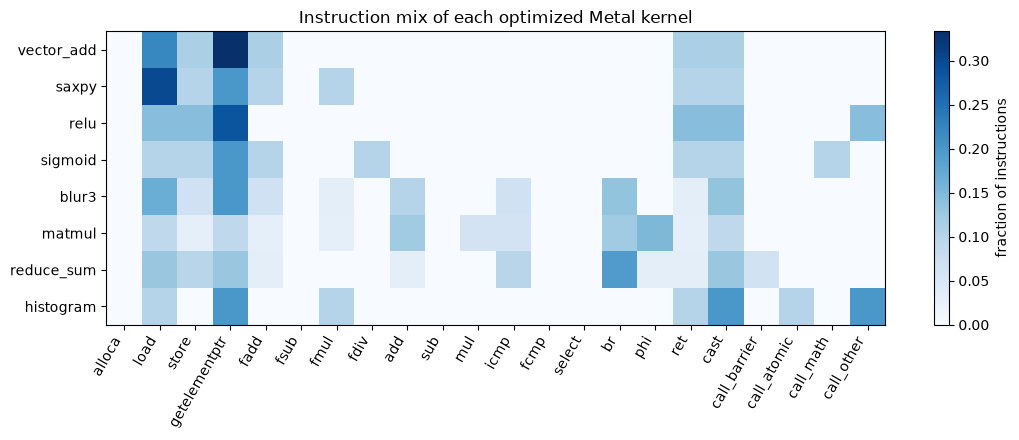

In [9]:
import os
os.makedirs("figures", exist_ok=True)
import matplotlib.pyplot as plt

opt = table["level"] == "opt"
names = list(table[opt]["kernel"])
opt_fractions = fractions[opt].values

plt.figure(figsize=(11, 4.5))
plt.imshow(opt_fractions, aspect="auto", cmap="Blues")
plt.colorbar(label="fraction of instructions")
plt.yticks(range(len(names)), names)
plt.xticks(range(len(FEATURES)), FEATURES, rotation=60, ha="right")
plt.title("Instruction mix of each optimized Metal kernel")
plt.tight_layout()
plt.savefig("figures/instruction_mix.png", dpi=150)
plt.show()

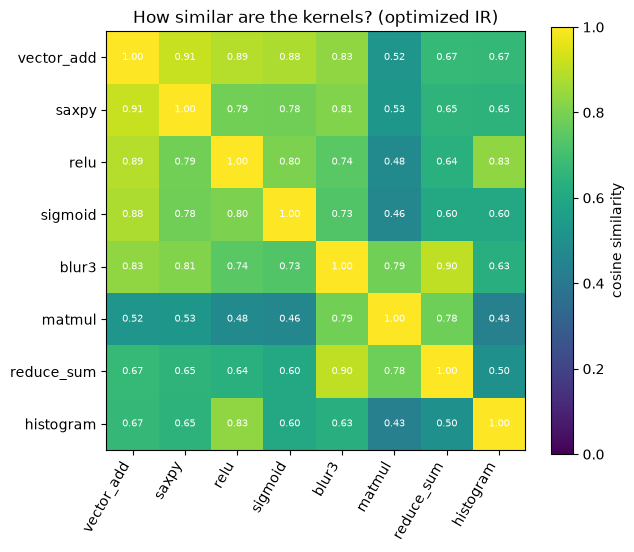

In [10]:
def cosine(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

n = len(names)
sim = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        sim[i, j] = cosine(opt_fractions[i], opt_fractions[j])

plt.figure(figsize=(6.5, 5.5))
plt.imshow(sim, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="cosine similarity")
plt.xticks(range(n), names, rotation=60, ha="right")
plt.yticks(range(n), names)
for i in range(n):
    for j in range(n):
        plt.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white")
plt.title("How similar are the kernels? (optimized IR)")
plt.tight_layout()
plt.savefig("figures/similarity.png", dpi=150)
plt.show()

The 2 PCA directions explain 70% of the variation


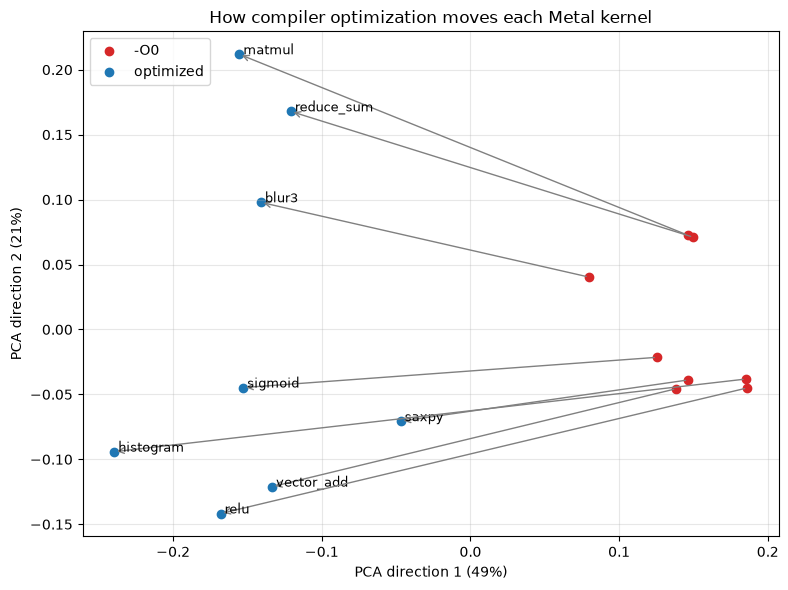

In [11]:
X = fractions.values                         # all 16 vectors (8 kernels x 2 levels)
X_centered = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
points = X_centered @ Vt[:2].T               # project onto the top-2 directions

explained = (S[:2] ** 2) / (S ** 2).sum()
print(f"The 2 PCA directions explain {100 * explained.sum():.0f}% of the variation")

plt.figure(figsize=(8, 6))
for name in kernels:
    i0 = table.index[(table["kernel"] == name) & (table["level"] == "O0")][0]
    i1 = table.index[(table["kernel"] == name) & (table["level"] == "opt")][0]
    plt.annotate("", xy=points[i1], xytext=points[i0],
                 arrowprops=dict(arrowstyle="->", color="gray"))
    plt.scatter(*points[i0], color="tab:red")
    plt.scatter(*points[i1], color="tab:blue")
    plt.text(points[i1][0], points[i1][1], " " + name, fontsize=9)

plt.scatter([], [], color="tab:red", label="-O0")
plt.scatter([], [], color="tab:blue", label="optimized")
plt.xlabel(f"PCA direction 1 ({100 * explained[0]:.0f}%)")
plt.ylabel(f"PCA direction 2 ({100 * explained[1]:.0f}%)")
plt.title("How compiler optimization moves each Metal kernel")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/optimization_arrows.png", dpi=150)
plt.show()

### Is the optimization direction consistent?

For each kernel, the change vector is (optimized − `-O0`). I compare each change vector with the average change using cosine similarity.

In [13]:
changes = {}
for name in kernels:
    v0 = fractions[(table["kernel"] == name) & (table["level"] == "O0")].values[0]
    v1 = fractions[(table["kernel"] == name) & (table["level"] == "opt")].values[0]
    changes[name] = v1 - v0

average_change = np.mean(list(changes.values()), axis=0)

print("Cosine similarity of each kernel's change with the average change:")
for name, change in changes.items():
    print(f"  {name:12s} {cosine(change, average_change):.2f}")

print("\nWhat the average change does (biggest moves):")
order = np.argsort(average_change)
for k in list(order[:4]) + list(order[-4:]):
    print(f"  {FEATURES[k]:15s} {average_change[k]:+.3f}")

Cosine similarity of each kernel's change with the average change:
  vector_add   0.89
  saxpy        0.88
  relu         0.94
  sigmoid      0.94
  blur3        0.85
  matmul       0.82
  reduce_sum   0.92
  histogram    0.90

What the average change does (biggest moves):
  alloca          -0.156
  load            -0.155
  store           -0.112
  sub             -0.005
  fadd            +0.032
  cast            +0.043
  ret             +0.052
  getelementptr   +0.118


## 8. Summary

See [README.md](README.md) for results and discussion.